# Лабораторная работа №1: Нелинейный регрессионный анализ
**Выполнил:** Курихин Максим Викторович
**Задача:** Сравнить классическую линейную модель и нелинейную модель аппроксимации методом наименьших квадратов на основе оптимального подбора физических параметров.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.optimize import curve_fit

## 1. Загрузка данных и первичный анализ

In [ ]:
# Загрузим датасет
df = pd.read_csv('..\\..\\tasks\\lab1\\dataset\\lab1-08.csv', header=None, names=['X', 'Y'])
print(f'Размерность данных: {df.shape}')
display(df.head())

Размерность данных: (200, 2)


,X,Y
0,7.393939,-4.832168
1,-2.595960,21.935301
2,-1.030303,8.319461
3,7.454545,-3.898417
4,-2.292929,16.866421


Визуализируем выборку, чтобы определить характер нелинейной зависимости.

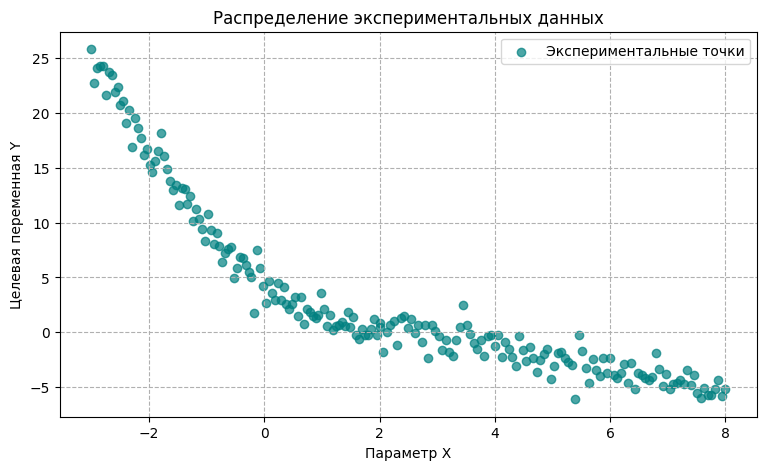

In [ ]:
plt.figure(figsize=(9, 5))
plt.scatter(df['X'], df['Y'], color='teal', alpha=0.7, label='Экспериментальные точки')
plt.title('Распределение экспериментальных данных')
plt.xlabel('Параметр X')
plt.ylabel('Целевая переменная Y')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

## 2. Разделение данных на выборки
Разобьем наши данные на обучающее подмножество и тестовое в классическом соотношении 80% на 20%.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df[['X']], df['Y'], test_size=0.2, random_state=42)
print(f'Обучающая выборка: {X_train.shape[0]} точек')
print(f'Тестовая выборка: {X_test.shape[0]} точек')

Обучающая выборка: 160 точек
Тестовая выборка: 40 точек


## 3. Модель №1: Стандартная линейная регрессия
Оценим качество приближения данных обычной прямой линией.

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_train_lr = lr.predict(X_train)
y_pred_test_lr = lr.predict(X_test)

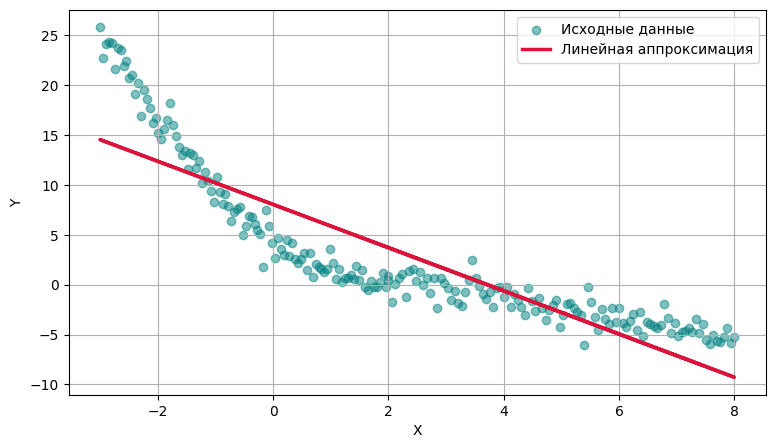

In [ ]:
plt.figure(figsize=(9, 5))
plt.scatter(df['X'], df['Y'], color='teal', alpha=0.5, label='Исходные данные')
plt.plot(df['X'], lr.predict(df[['X']]), color='crimson', linewidth=2.5, label='Линейная аппроксимация')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Оценка метрик для линейной регрессии
mse_train_lr = mean_squared_error(y_train, y_pred_train_lr)
mae_train_lr = mean_absolute_error(y_train, y_pred_train_lr)

mse_test_lr = mean_squared_error(y_test, y_pred_test_lr)
mae_test_lr = mean_absolute_error(y_test, y_pred_test_lr)

metrics_lr = pd.DataFrame({
    'Метрика': ['MSE', 'MAE'],
    'Обучающая выборка': [mse_train_lr, mae_train_lr],
    'Тестовая выборка': [mse_test_lr, mae_test_lr]
})
display(metrics_lr)

,Метрика,Обучающая выборка,Тестовая выборка
0,MSE,13.907373,14.318346
1,MAE,3.056009,2.895890


Как видно по метрикам, линейная регрессия выдает довольно плохие результаты. Ошибки получились большими, но это в принципе ожидаемо, так как наши исходные данные имеют явно нелинейную форму, и обычная прямая линия тут никак не может нормально описать зависимость.

## 4. Модель №2: Улучшенный линейный бейзлайн (Полиномиальная регрессия)

Чтобы как-то улучшить результаты и учесть изгиб графика, попробуем добавить полиномиальные признаки (степени числа). Чтобы модель не переобучалась, объединим создание признаков и регуляризацию Ridge в один pipeline и подберем лучшие параметры (степень и коэффициент регуляризации) через обычный поиск по сетке GridSearchCV.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Создаем конвейер: полиномиальные признаки -> Ridge регрессия
pipeline = Pipeline([
    ('poly', PolynomialFeatures()),
    ('ridge', Ridge())
])

# Задаем сетку параметров для поиска
param_grid = {
    'poly__degree': [2, 3, 4, 5, 6],
    'ridge__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Настраиваем поиск по сетке
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
best_poly_model = grid_search.best_estimator_

Лучшие параметры: {'poly__degree': 6, 'ridge__alpha': 0.1}


Визуализируем предсказания нашей улучшенной полиномиальной модели.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


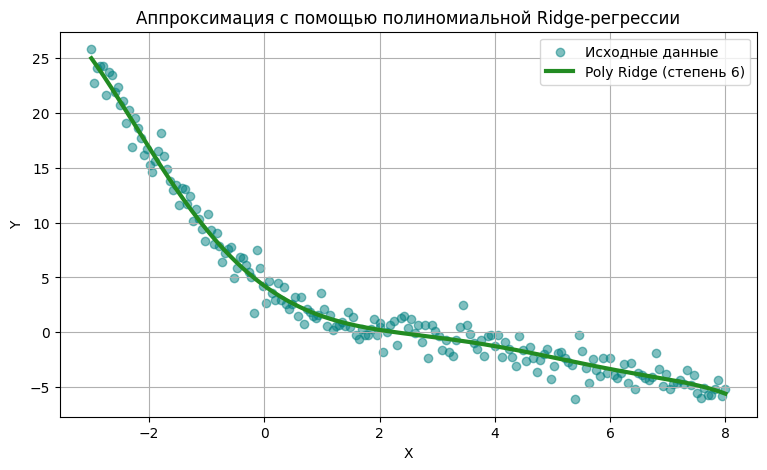

In [ ]:
x_plot = np.linspace(df['X'].min(), df['X'].max(), 500).reshape(-1, 1)
y_plot_poly = best_poly_model.predict(x_plot)

plt.figure(figsize=(9, 5))
plt.scatter(df['X'], df['Y'], color='teal', alpha=0.5, label='Исходные данные')
plt.plot(x_plot, y_plot_poly, color='forestgreen', linewidth=3, label=f"Poly Ridge (степень {grid_search.best_params_['poly__degree']})")
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.title('Аппроксимация с помощью полиномиальной Ridge-регрессии')
plt.show()

Рассчитаем качество предсказаний на обучающей и тестовой выборках для полиномиальной модели.

In [ ]:
y_pred_train_poly = best_poly_model.predict(X_train)
y_pred_test_poly = best_poly_model.predict(X_test)

mse_train_poly = mean_squared_error(y_train, y_pred_train_poly)
mae_train_poly = mean_absolute_error(y_train, y_pred_train_poly)

mse_test_poly = mean_squared_error(y_test, y_pred_test_poly)
mae_test_poly = mean_absolute_error(y_test, y_pred_test_poly)

metrics_poly = pd.DataFrame({
    'Метрика': ['MSE', 'MAE'],
    'Обучающая выборка': [mse_train_poly, mae_train_poly],
    'Тестовая выборка': [mse_test_poly, mae_test_poly]
})
display(metrics_poly)

,Метрика,Обучающая выборка,Тестовая выборка
0,MSE,0.953646,1.298145
1,MAE,0.765954,0.837103


### Оценка результатов
Мы подобрали параметры для Ridge-регрессии с полиномиальными фичами и получили неплохое предсказание, при этом сама модель осталась линейной.

## 5. Выводы

В этой работе мы сравнили два простых подхода:

1. Простая линейная регрессия:
- Пытается провести обычную прямую линию там, где идет изгиб.
- Ошибки получились огромными (MSE на тесте около 14.32, MAE около 2.90).
- На графике сразу видно, что прямая линия тут вообще не подходит.

2. Полиномиальная регрессия с регуляризацией Ridge:
- За счет добавления степеней (лучше всего подошла 6 степень) модель смогла хорошо подстроиться под кривую на графике.
- Параметр регуляризации подобрался 0.1, что помогло не переобучить модель.
- Результаты стали намного лучше: MSE на тесте упал до 1.30, а MAE до 0.84.

В итоге, если добавить к обычной линейной модели полиномиальные признаки и немного настроить параметры, то можно вполне хорошо описать кривые данные.